In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import recall_score, precision_score
from sklearn.metrics import confusion_matrix

# Task1: Train a model that will predict the cut of each diamond.
- Train the model

- Find out the feature importance

- Make predictions for the test sample

- Visualise the confusion matrix for the test data

- Compute the accuracy, precision, recall and F1

In [45]:
diamonds = sns.load_dataset('diamonds')
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [46]:
diamonds['cut'].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [47]:
diamonds.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [48]:
diamonds.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='str')

## Define the target and the features

In [49]:
# Define the target and the features
target = "cut"

classifier_features = ["color", "clarity"]
numeric_features = ["carat", "depth", "table", "x", "y", "z"]

X = diamonds[classifier_features + numeric_features]
y = diamonds[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), classifier_features),
        ("numeric", "passthrough", numeric_features),
    ]
)

## Train the model

In [50]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

## Evaluate the model

### Multiclass

Precision and recall require an additional parameter: average.

**Average** parameter is required for multiclass/multilabel targets. {‘micro’, ‘macro’, ‘samples’, ‘weighted’, ‘binary’} or None, default=’binary’

- 'micro':
Calculate metrics globally by counting the total true positives, false negatives and false positives.

- 'macro':
Calculate metrics for each label, and find their unweighted mean. This does not take label imbalance into account.

Documentation for recall: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html

In [51]:
y_predicted = model.predict(X_test)

averages = ["micro", "macro", "weighted"]
metrics = pd.DataFrame(
    {
        "precision": [
            precision_score(y_test, y_predicted, average=average, zero_division=0)
            for average in averages
        ],
        "recall": [
            recall_score(y_test, y_predicted, average=average, zero_division=0)
            for average in averages
        ],
        "F1": [
            f1_score(y_test, y_predicted, average=average, zero_division=0)
            for average in averages
        ],
    },
    index=averages,
)
metrics.index.name = "averaging method"

accuracy = accuracy_score(y_test, y_predicted)
print(f"Accuracy: {accuracy:.4f}")
metrics

Accuracy: 0.7056


,precision,recall,F1
averaging method,,,
micro,0.705599,0.705599,0.705599
macro,0.709436,0.712068,0.710734
weighted,0.706138,0.705599,0.705856


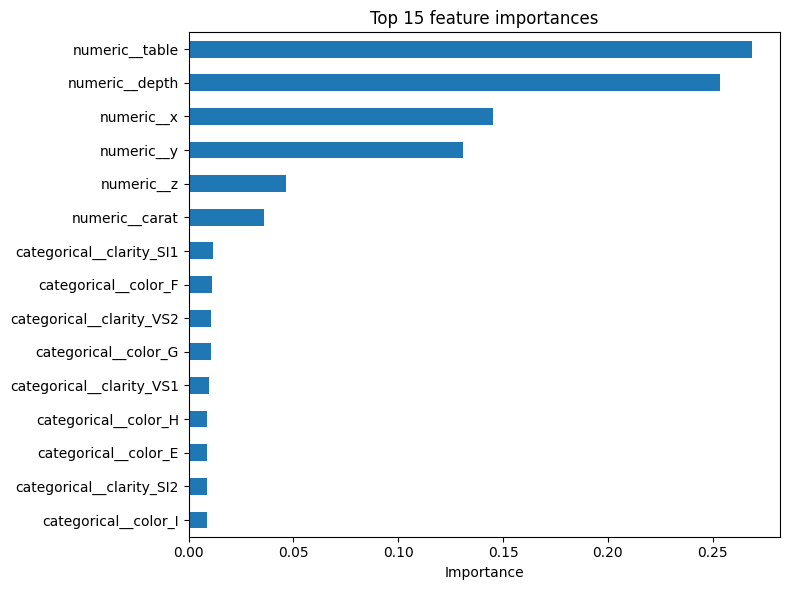

In [52]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
feature_importances = pd.Series(
    model.named_steps["classifier"].feature_importances_, index=feature_names
).sort_values(ascending=False)

top_features = feature_importances.head(15).sort_values()
top_features.plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

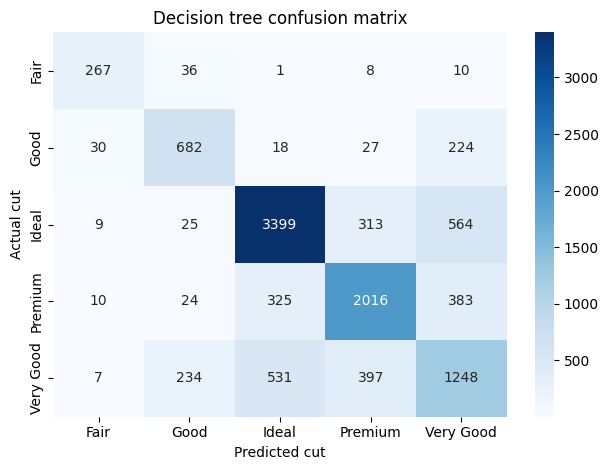

In [53]:
class_labels = model.named_steps["classifier"].classes_
confusion = confusion_matrix(y_test, y_predicted, labels=class_labels)

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.xlabel("Predicted cut")
plt.ylabel("Actual cut")
plt.title("Decision tree confusion matrix")
plt.tight_layout()
plt.show()

#### Task2: Choose 2 ensemble models and train them on the diamonds dataset.

* Play with the model's parameters(check the documentation)
* Compare their accuracy, precision, recall, and F1 scores for the training and test sets.
* Compare their confusion matrix for the test sample.
* Compare the stability of each model using cross-validation.

- Documentation - Random Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- Documentation - AdaBoost:  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
- Documentation - BaggingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html
- Documentation - GradientBoosting: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html#sklearn.ensemble.GradientBoostingClassifier
- Documentation - VotingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html
- Documentation - StackingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

### Random Forest and Gradient Boosting

Run Task 1 first: we reuse its features and stratified train/test split for a fair comparison.

- **Random Forest** averages votes from trees trained on different bootstrap samples. Try changing `n_estimators`, `max_depth`, or `min_samples_leaf`.
- **Gradient Boosting** adds trees sequentially to improve earlier predictions. Try changing `n_estimators`, `learning_rate`, or `max_depth`.
- Each model gets its own cloned preprocessor. Keeping preprocessing inside the pipeline also prevents leakage between cross-validation folds.
- Compare training and test scores: a large gap can indicate overfitting. Macro scores give every cut equal weight; weighted scores account for class frequency.
- Cross-validation uses only the training data. Higher mean scores indicate better performance; lower fold-to-fold standard deviation indicates more consistent scores on these splits. Use cross-validation, rather than repeatedly checking the test set, to guide parameter changes.

In [54]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

ensemble_models = {
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100, max_depth=None, min_samples_leaf=2,
            random_state=42, n_jobs=2,
        )),
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.1, max_depth=3,
            random_state=42,
        )),
    ]),
}

ensemble_models["Random Forest - depth 20"] = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=2,
    )),
])

ensemble_models["Gradient Boosting - depth 2"] = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=2,
        random_state=42,
    )),
])

comparison_rows = []
ensemble_predictions = {}
for name, ensemble in ensemble_models.items():
    ensemble.fit(X_train, y_train)
    ensemble_predictions[name] = {}
    for split, X_split, y_split in [
        ("train", X_train, y_train), ("test", X_test, y_test)
    ]:
        predictions = ensemble.predict(X_split)
        ensemble_predictions[name][split] = predictions
        for average in ["micro", "macro", "weighted"]:
            comparison_rows.append({
                "model": name, "split": split, "average": average,
                "accuracy": accuracy_score(y_split, predictions),
                "precision": precision_score(
                    y_split, predictions, average=average, zero_division=0
                ),
                "recall": recall_score(
                    y_split, predictions, average=average, zero_division=0
                ),
                "F1": f1_score(
                    y_split, predictions, average=average, zero_division=0
                ),
            })

ensemble_metrics = pd.DataFrame(comparison_rows).set_index(
    ["model", "split", "average"]
)
ensemble_metrics

accuracy  precision    recall  \
model                       split average                                   
Random Forest               train micro     0.920884   0.920884  0.920884   
                                  macro     0.920884   0.940283  0.915176   
                                  weighted  0.920884   0.922823  0.920884   
                            test  micro     0.762792   0.762792  0.762792   
                                  macro     0.762792   0.774804  0.739221   
                                  weighted  0.762792   0.754924  0.762792   
Gradient Boosting           train micro     0.760776   0.760776  0.760776   
                                  macro     0.760776   0.784780  0.742335   
                                  weighted  0.760776   0.756937  0.760776   
                            test  micro     0.757694   0.757694  0.757694   
                                  macro     0.757694   0.781508  0.738889   
                                  weighted  0.757694   0.754412  0.757694   
Random Forest - depth 20    train micro     0.871362   0.871362  0.871362   
                                  macro     0.871362   0.906732  0.869026   
                                  weighted  0.871362   0.877790  0.871362   
                            test  micro     0.759362   0.759362  0.759362   
                                  macro     0.759362   0.777042  0.735786   
                                  weighted  0.759362   0.752857  0.759362   
Gradient Boosting - depth 2 train micro     0.743326   0.743326  0.743326   
                                  macro     0.743326   0.764668  0.721548   
                                  weighted  0.743326   0.738634  0.743326   
                            test  micro     0.742121   0.742121  0.742121   
                                  macro     0.742121   0.765006  0.722659   
                                  weighted  0.742121   0.738308  0.742121   

                                                  F1  
model                       split average             
Random Forest               train micro     0.920884  
                                  macro     0.926310  
                                  weighted  0.920166  
                            test  micro     0.762792  
                                  macro     0.750554  
                                  weighted  0.751634  
Gradient Boosting           train micro     0.760776  
                                  macro     0.751453  
                                  weighted  0.746991  
                            test  micro     0.757694  
                                  macro     0.747907  
                                  weighted  0.743430  
Random Forest - depth 20    train micro     0.871362  
                                  macro     0.882539  
                                  weighted  0.868496  
                            test  micro     0.759362  
                                  macro     0.747169  
                                  weighted  0.745862  
Gradient Boosting - depth 2 train micro     0.743326  
                                  macro     0.727394  
                                  weighted  0.725166  
                            test  micro     0.742121  
                                  macro     0.727567  
                                  weighted  0.723293

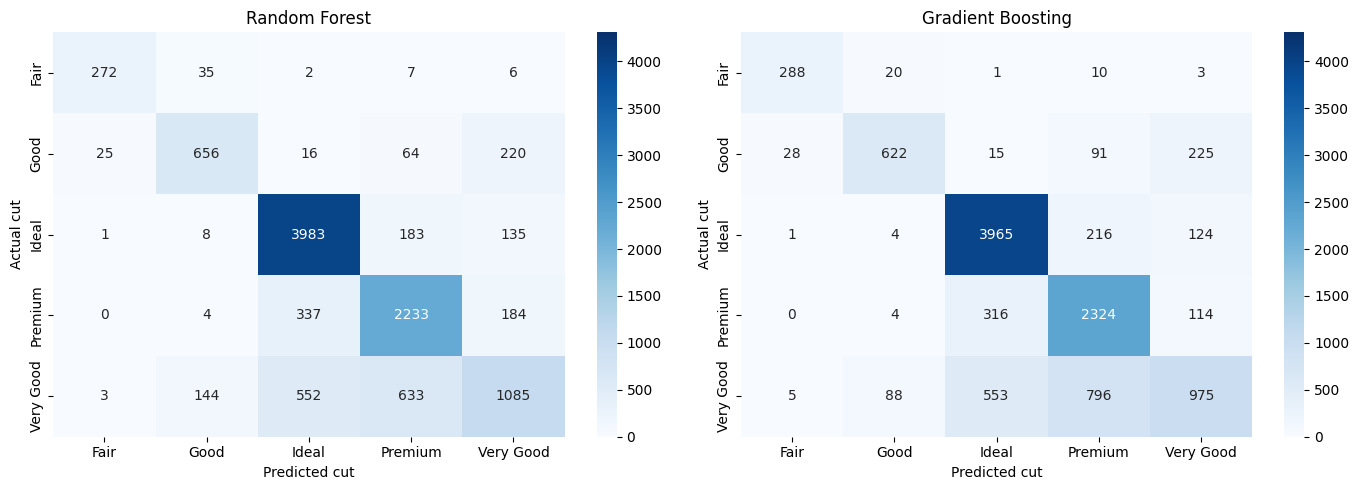

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cut_labels = sorted(y_train.unique())
for ax, name in zip(axes, ensemble_models):
    matrix = confusion_matrix(
        y_test, ensemble_predictions[name]["test"], labels=cut_labels
    )
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=cut_labels, yticklabels=cut_labels,
        vmin=0, vmax=y_test.value_counts().max(),
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted cut")
    ax.set_ylabel("Actual cut")
plt.tight_layout()
plt.show()

In [56]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_rows = []
for name, ensemble in ensemble_models.items():
    scores = cross_validate(
        ensemble, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "F1_macro": "f1_macro"},
        n_jobs=1, error_score="raise",
    )
    for fold in range(cv.get_n_splits()):
        cv_rows.append({
            "model": name, "fold": fold + 1,
            "accuracy": scores["test_accuracy"][fold],
            "F1_macro": scores["test_F1_macro"][fold],
        })

cv_results = pd.DataFrame(cv_rows)
print("Individual fold scores:")
print(cv_results.to_string(index=False))
cv_summary = cv_results.groupby("model")[["accuracy", "F1_macro"]].agg(
    ["mean", "std"]
)
cv_summary

Individual fold scores:
                      model  fold  accuracy  F1_macro
              Random Forest     1  0.756813  0.741698
              Random Forest     2  0.757856  0.736608
              Random Forest     3  0.750904  0.731523
          Gradient Boosting     1  0.757856  0.747078
          Gradient Boosting     2  0.756048  0.739858
          Gradient Boosting     3  0.748401  0.731335
   Random Forest - depth 20     1  0.753268  0.735197
   Random Forest - depth 20     2  0.755701  0.733281
   Random Forest - depth 20     3  0.746593  0.722880
Gradient Boosting - depth 2     1  0.741588  0.729319
Gradient Boosting - depth 2     2  0.742700  0.722525
Gradient Boosting - depth 2     3  0.735957  0.714673


accuracy            F1_macro          
                                 mean       std      mean       std
model                                                              
Gradient Boosting            0.754102  0.005019  0.739424  0.007881
Gradient Boosting - depth 2  0.740082  0.003615  0.722172  0.007330
Random Forest                0.755191  0.003749  0.736610  0.005088
Random Forest - depth 20     0.751854  0.004715  0.730453  0.006628

# Hyperparameter optimisation

In [57]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

#### Task3: Find the best hyperparameter for an ensemble from above.